# Projeto 2 – Classificação de toxicidade em tweets (ToLD-Br)

Objetivo: predizer se um tweet em português é **tóxico** e, se for, **de que tipo**, a partir do texto (TF-IDF),
comparando **Logistic Regression com Gradient Descent** (LR-GD, scikit-learn) e uma **Árvore de Decisão (AD)
implementada do zero** (treino e predição).

Base: [ToLD-Br](https://github.com/joaoaleite/ToLD-Br) – 21 mil tweets anotados por 3 anotadores em 6 categorias
(homofobia, obscenidade, insulto, racismo, misoginia, xenofobia).

# Carga dos dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# lê o CSV direto do repositório do ToLD-Br (funciona no Colab sem precisar subir arquivos)
URL = "https://raw.githubusercontent.com/joaoaleite/ToLD-Br/main/ToLD-BR.csv"
df = pd.read_csv(URL)
print(df.shape)
df.head()

(21000, 7)


,text,homophobia,obscene,insult,racism,misogyny,xenophobia
0,Meu nivel de amizade com isis é ela ter meu in...,0.0,0.0,2.0,0.0,0.0,0.0
1,"rt @user @user o cara adultera dados, que fora...",0.0,0.0,1.0,0.0,0.0,0.0
2,@user @user @user o cara só é simplesmente o m...,0.0,2.0,1.0,0.0,0.0,0.0
3,eu to chorando vei vsf e eu nem staneio izone ...,0.0,1.0,0.0,0.0,0.0,0.0
4,Eleitor do Bolsonaro é tão ignorante q não per...,0.0,1.0,2.0,0.0,0.0,0.0


# Criação da coluna única de classe (rótulo multiclasse)

O ToLD-Br é multirrótulo (6 colunas com votos de 0 a 3 anotadores); aqui viro isso em uma única
classe por tweet: a categoria mais votada se ao menos 2 anotadores concordaram, senão "nenhuma".

In [2]:
cols = ["homophobia", "obscene", "insult", "racism", "misogyny", "xenophobia"]

maior = df[cols].max(axis=1)
df["classe"] = np.where(maior >= 2, df[cols].idxmax(axis=1), "nenhuma")

print(df["classe"].value_counts())

classe
nenhuma       16937
obscene        2296
insult         1502
homophobia      169
misogyny         44
xenophobia       31
racism           21
Name: count, dtype: int64


# Estudo Introdutório

In [3]:
# ## Estudo introdutório: visão geral da base
# Mostra tamanho, colunas, tipos, nulos, duplicados e distribuição (absoluta e %) das classes.

print("Formato:", df.shape)
print("\nColunas:", list(df.columns))
print("\nNulos por coluna:\n", df.isnull().sum())
print("\nTextos duplicados:", df["text"].duplicated().sum())

dist = df["classe"].value_counts()
print("\nDistribuição das classes:")
print(pd.DataFrame({"qtd": dist, "%": (dist / len(df) * 100).round(2)}))

Formato: (21000, 8)

Colunas: ['text', 'homophobia', 'obscene', 'insult', 'racism', 'misogyny', 'xenophobia', 'classe']

Nulos por coluna:
 text          0
homophobia    0
obscene       0
insult        0
racism        0
misogyny      0
xenophobia    0
classe        0
dtype: int64

Textos duplicados: 187

Distribuição das classes:
              qtd      %
classe                  
nenhuma     16937  80.65
obscene      2296  10.93
insult       1502   7.15
homophobia    169   0.80
misogyny       44   0.21
xenophobia     31   0.15
racism         21   0.10


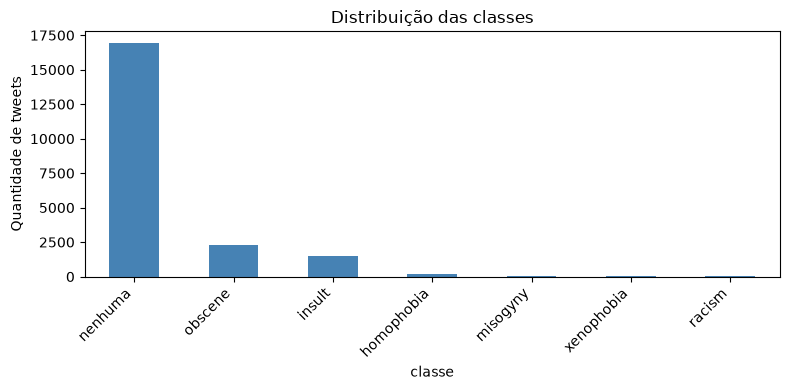

In [4]:
# ## Estudo introdutório: gráfico de distribuição das classes
# Barras com a quantidade de tweets por classe, para visualizar o desbalanceamento.

import matplotlib.pyplot as plt

dist.plot(kind="bar", figsize=(8, 4), color="steelblue")
plt.title("Distribuição das classes")
plt.ylabel("Quantidade de tweets")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [5]:
# ## Estudo introdutório: tamanho dos textos
# Calcula nº de palavras por tweet e mostra estatísticas gerais e a média por classe.

df["n_palavras"] = df["text"].str.split().str.len()

print(df["n_palavras"].describe())
print("\nMédia de palavras por classe:")
print(df.groupby("classe")["n_palavras"].mean().round(1))

count    21000.000000
mean        15.628905
std         11.655742
min          1.000000
25%          7.000000
50%         12.000000
75%         20.000000
max         67.000000
Name: n_palavras, dtype: float64

Média de palavras por classe:
classe
homophobia    14.2
insult        16.6
misogyny      13.4
nenhuma       15.6
obscene       15.2
racism        14.7
xenophobia    16.1
Name: n_palavras, dtype: float64


In [6]:
# ## Estudo introdutório: exemplos por classe
# Imprime 2 tweets aleatórios de cada classe para entender qualitativamente o conteúdo.

for c in df["classe"].unique():
    print(f"\n=== {c} ===")
    for t in df[df["classe"] == c]["text"].sample(2, random_state=42):
        print("-", t[:200])


=== insult ===
- vai se fuder que time ruim cadê o freire e o hawk seus zé ruela
- jr some, mermão pqp

=== nenhuma ===
- @user mal posso esperar pra taebaekai dar dinheiro pra esse unit e as fãs da sm inda falarem mal
- @user corre que a federal t谩 chegando

=== obscene ===
- meu melhor amigo tá namorando vai se fuder aaaaaa😍😍
- @user para o redpass dá o cu ao vieira.

=== xenophobia ===
- @user carioca é dramático demais.....😂😂😂😂😂 https://t.co/onxd1dalu6
- rt @user @user @user hahahahahahahahahah completamente bitolado. bolha f茅tida paulista. vcs nunca v茫o manipular a hist贸ria!

=== racism ===
- Segue minha página de shitpost @user
Mas é de humor negro/shitpost então se tu não gosta sai

Eu divido essa página com a minha melhor amiga segue ela tbm @user :&gt;
- satisfação da porra quando o django mete o cassete nos brancos.

=== homophobia ===
- @user @user agr pergunta quantos são sócios/vao aos jogos 
torcida viadinha tnc
- rt @user sonho de toda bichinha otaria  https://t.co/egm5

# Remoção de Textos Duplicados

In [7]:
# ## Remoção de textos duplicados
# Remove tweets com texto repetido (mantém o primeiro) para evitar o mesmo texto cair em treino e teste.

antes = len(df)
df = df.drop_duplicates(subset="text", keep="first").reset_index(drop=True)
print(f"Removidos: {antes - len(df)} | Restantes: {len(df)}")

Removidos: 187 | Restantes: 20813


In [8]:
# ## Agrupamento das classes minoritárias
# Junta racism, xenophobia e misogyny em "odio_identitario", pois sozinhas têm poucos exemplos para split e métricas confiáveis.

df["classe"] = df["classe"].replace({
    "racism": "odio_identitario",
    "xenophobia": "odio_identitario",
    "misogyny": "odio_identitario",
})

dist = df["classe"].value_counts()
print(pd.DataFrame({"qtd": dist, "%": (dist / len(df) * 100).round(2)}))

                    qtd      %
classe                        
nenhuma           16783  80.64
obscene            2276  10.94
insult             1489   7.15
homophobia          169   0.81
odio_identitario     96   0.46


Rodar Novamente o Gráfico de Distribuição

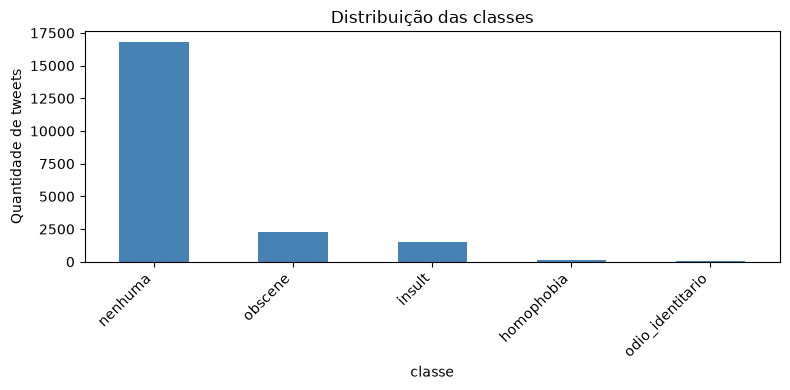

In [9]:
# ## Estudo introdutório: gráfico de distribuição das classes
# Barras com a quantidade de tweets por classe, para visualizar o desbalanceamento.

import matplotlib.pyplot as plt

dist.plot(kind="bar", figsize=(8, 4), color="steelblue")
plt.title("Distribuição das classes")
plt.ylabel("Quantidade de tweets")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Com o agrupamento ficamos com **5 classes** (requisito do projeto): `nenhuma`, `obscene`, `insult`, `homophobia`
e `odio_identitario`. Qualquer classe diferente de `nenhuma` é um tweet **tóxico** – essa visão binária
(tóxico × não tóxico), que é a tarefa principal do ToLD-Br original, é avaliada no final.

# Split 60/20/20

In [10]:
# ## Split estratificado 60/20/20
# Divide em treino (60%), validação (20%) e teste (20%) mantendo a proporção das classes em cada parte.

from sklearn.model_selection import train_test_split

SEED = 42

X = df["text"]
y = df["classe"]

# 1) separa 20% para teste
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

# 2) do restante (80%), separa 25% para validação (= 20% do total)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=SEED
)

print(f"Treino: {len(X_train)} | Validação: {len(X_val)} | Teste: {len(X_test)}")

Treino: 12487 | Validação: 4163 | Teste: 4163


In [11]:
# ## Conferência do split
# Mostra a quantidade de tweets por classe em treino, validação e teste para checar a estratificação.

conf = pd.DataFrame({
    "treino": y_train.value_counts(),
    "validacao": y_val.value_counts(),
    "teste": y_test.value_counts(),
})
print(conf)

                  treino  validacao  teste
classe                                    
nenhuma            10069       3357   3357
obscene             1366        455    455
insult               893        298    298
homophobia           101         34     34
odio_identitario      58         19     19


# TF-IDF sobre os textos

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

# ## TF-IDF com limpeza (opcional)
# Refaz o TF-IDF removendo termos numéricos e muito frequentes (max_df), mantendo só palavras de pelo menos 2 letras.

tfidf = TfidfVectorizer(
    max_features=5000, ngram_range=(1, 2), min_df=2, max_df=0.5,
    lowercase=True, token_pattern=r"(?u)\b[^\W\d_]{2,}\b"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

termos = tfidf.get_feature_names_out()
print("Formato treino:", X_train_tfidf.shape)
print("Amostra de termos:", list(termos[:20]))

Formato treino: (12487, 5000)
Amostra de termos: ['aaa', 'aaaa', 'aaaaaa', 'abel', 'aberração', 'abraço', 'abre', 'abri', 'abrir', 'abriu', 'absolutamente', 'absurdo', 'absurdos', 'acaba', 'acabando', 'acabar', 'acabar com', 'acabei', 'acabei de', 'acabo']


In [13]:
# ## Termos mais relevantes do TF-IDF
# Lista os 20 termos com maior peso médio no treino.

pesos = np.asarray(X_train_tfidf.mean(axis=0)).ravel()
top = np.argsort(pesos)[::-1][:20]
print("Top 20 termos por peso médio:", [termos[i] for i in top])

# rótulos como array para poder fatiar por posição (X_train[:m], y_train[:m])
y_train, y_val, y_test = np.asarray(y_train), np.asarray(y_val), np.asarray(y_test)

Top 20 termos por peso médio: ['user', 'que', 'de', 'eu', 'user user', 'https', 'co', 'https co', 'rt', 'rt user', 'do', 'não', 'pqp', 'pra', 'da', 'no', 'porra', 'um', 'caralho', 'com']


# Modelos

## Logistic Regression com Gradient Descent

`SGDClassifier(loss="log_loss")` é a regressão logística treinada por gradiente descendente estocástico.
As quatro variações diferem só no termo de regularização (sem, Ridge/L2, Lasso/L1, Elastic Net/L1+L2).
`class_weight="balanced"` compensa o desbalanceamento das classes.

In [14]:
# ## LR-GD sem regularização, Ridge, Lasso e Elastic Net
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import f1_score

configs = {
    "sem_reg":     dict(penalty=None),
    "ridge":       dict(penalty="l2", alpha=1e-4),
    "lasso":       dict(penalty="l1", alpha=1e-4),
    "elastic_net": dict(penalty="elasticnet", alpha=1e-4, l1_ratio=0.5),
}

def nova_lr(nome):
    return SGDClassifier(loss="log_loss", class_weight="balanced",
                         max_iter=1000, tol=1e-3, random_state=SEED, **configs[nome])

## Árvore de Decisão (implementação própria – CART)

Seguindo a aula de Árvore de Decisão:

* **Impureza de Gini** do nó *i*: $G_i = 1 - \sum_{k=1}^{n} p_{i,k}^2$
* **CART**: em cada nó procura o par (atributo *k*, limiar *t_k*) que gera os dois subconjuntos mais puros,
  minimizando $J(k, t_k) = \frac{m_{esq}}{m} G_{esq} + \frac{m_{dir}}{m} G_{dir}$.
* A construção é **recursiva** e para quando chega em `max_depth`, quando o nó é puro, ou quando não há corte que reduza a impureza.
* **Predição**: a árvore é varrida da raiz até uma folha; a classe é a majoritária da folha e a
  probabilidade (`predict_proba`) é a proporção de cada classe entre as instâncias de treino daquela folha.

Como os atributos são pesos TF-IDF (a maioria zero), os limiares candidatos são poucos valores fixos
(`0.0` = "o termo aparece no tweet", `0.1`, `0.2`, `0.3`). Para cada limiar, a contagem de classes de **todos**
os atributos é calculada de uma vez com uma multiplicação de matrizes, o que deixa o treino rápido.

In [15]:
# ## Árvore de Decisão: treino (fit) e predição (predict / predict_proba)

def gini(contagens):
    # G = 1 - soma(p_k^2), calculado linha a linha (um nó/atributo por linha)
    n = contagens.sum(axis=-1, keepdims=True)
    p = contagens / np.maximum(n, 1)
    return 1 - (p ** 2).sum(axis=-1)


class ArvoreDecisao:
    def __init__(self, max_depth=None, min_samples_split=2, limiares=(0.0, 0.1, 0.2, 0.3)):
        self.max_depth = max_depth if max_depth is not None else np.inf
        self.min_samples_split = min_samples_split
        self.limiares = limiares

    # ---------- treino ----------
    def fit(self, X, y):
        self.classes_, y_idx = np.unique(y, return_inverse=True)
        Y = np.eye(len(self.classes_))[y_idx]          # one-hot: contagem de classes = soma das linhas
        self.raiz = self._construir(X.tocsr(), Y, profundidade=0)
        return self

    def _melhor_corte(self, X, Y):
        total = Y.sum(axis=0)
        m = len(Y)
        melhor_imp, melhor_k, melhor_t = gini(total), None, None
        for t in self.limiares:
            dir_ = np.asarray((X > t).T @ Y)           # contagem de classes com x_k > t, para todo atributo k
            esq = total - dir_
            m_dir = dir_.sum(axis=1)
            m_esq = m - m_dir
            imp = (m_esq * gini(esq) + m_dir * gini(dir_)) / m
            imp[(m_dir == 0) | (m_esq == 0)] = np.inf  # corte que não divide nada
            k = int(np.argmin(imp))
            if imp[k] < melhor_imp - 1e-12:
                melhor_imp, melhor_k, melhor_t = imp[k], k, t
        return melhor_k, melhor_t

    def _construir(self, X, Y, profundidade):
        cont = Y.sum(axis=0)
        no = {"proba": cont / cont.sum(), "classe": int(np.argmax(cont))}
        if (profundidade >= self.max_depth or len(Y) < self.min_samples_split
                or cont.max() == len(Y)):            # nó puro
            return no                                  # nó folha
        k, t = self._melhor_corte(X, Y)
        if k is None:                                  # nenhum corte reduz a impureza
            return no
        vai_dir = (X[:, k] > t).toarray().ravel()
        no["k"], no["t"] = k, t
        no["esq"] = self._construir(X[~vai_dir], Y[~vai_dir], profundidade + 1)
        no["dir"] = self._construir(X[vai_dir], Y[vai_dir], profundidade + 1)
        return no

    # ---------- predição ----------
    def _folha(self, x):
        no = self.raiz
        while "k" in no:                               # desce até um nó folha
            no = no["dir"] if x[0, no["k"]] > no["t"] else no["esq"]
        return no

    def predict_proba(self, X):
        X = X.tocsr()
        return np.array([self._folha(X[i])["proba"] for i in range(X.shape[0])])

    def predict(self, X):
        X = X.tocsr()
        return self.classes_[[self._folha(X[i])["classe"] for i in range(X.shape[0])]]

    def altura(self, no=None):
        no = self.raiz if no is None else no
        return 0 if "k" not in no else 1 + max(self.altura(no["esq"]), self.altura(no["dir"]))

In [16]:
# ## Teste rápido da árvore: mostra os primeiros cortes aprendidos

arv = ArvoreDecisao(max_depth=3).fit(X_train_tfidf, y_train)

def mostrar(no, nivel=0):
    pad = "    " * nivel
    if "k" not in no:
        print(f"{pad}folha -> {arv.classes_[no['classe']]}  (p={no['proba'].max():.2f})")
        return
    print(f"{pad}'{termos[no['k']]}' > {no['t']}?")
    mostrar(no["dir"], nivel + 1)
    print(f"{pad}senão:")
    mostrar(no["esq"], nivel + 1)

mostrar(arv.raiz)
print("\nF1 macro na validação (profundidade 3):", f1_score(y_val, arv.predict(X_val_tfidf), average="macro"))

'cu' > 0.0?
    'seu' > 0.0?
        'vai tomar' > 0.3?
            folha -> insult  (p=0.67)
        senão:
            folha -> obscene  (p=0.81)
    senão:
        'eu' > 0.1?
            folha -> nenhuma  (p=0.60)
        senão:
            folha -> obscene  (p=0.53)
senão:
    'da puta' > 0.0?
        'co' > 0.1?
            folha -> insult  (p=0.82)
        senão:
            folha -> nenhuma  (p=0.45)
    senão:
        'buceta' > 0.0?
            folha -> obscene  (p=0.80)
        senão:
            folha -> nenhuma  (p=0.84)



F1 macro na validação (profundidade 3): 0.24198012383054918


# Curvas de aprendizado

Função adaptada do slide *Curvas de Aprendizado* (aula de Regularização): em vez de separar treino/validação
dentro da função, usa os conjuntos já definidos no split 60/20/20, e no lugar do RMSE (regressão) usa
**erro = 1 − F1 macro** (classificação com classes desbalanceadas). Para não treinar um modelo por instância,
o tamanho do treino cresce em 10 passos (10%, 20%, …, 100% do treino).

In [17]:
# ## Função de curva de aprendizado (baseada no slide)

def plot_learning_curves(model, X_train, y_train, X_val, y_val, titulo):
    train_errors, val_errors = [], []
    tamanhos = (np.linspace(0.1, 1.0, 10) * X_train.shape[0]).astype(int)
    for m in tamanhos:
        model.fit(X_train[:m], y_train[:m])
        y_train_predict = model.predict(X_train[:m])
        y_val_predict = model.predict(X_val)
        train_errors.append(1 - f1_score(y_train[:m], y_train_predict, average="macro"))
        val_errors.append(1 - f1_score(y_val, y_val_predict, average="macro"))
    plt.figure(figsize=(7, 4))
    plt.plot(tamanhos, train_errors, "r-+", linewidth=2, label="train")
    plt.plot(tamanhos, val_errors, "b-", linewidth=3, label="val")
    plt.xlabel("Tamanho do conjunto de treino")
    plt.ylabel("Erro (1 - F1 macro)")
    plt.title(titulo)
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
    print(f"Último ponto -> erro treino: {train_errors[-1]:.3f} | erro validação: {val_errors[-1]:.3f}")

## Gráfico 1: LR-GD sem regularização

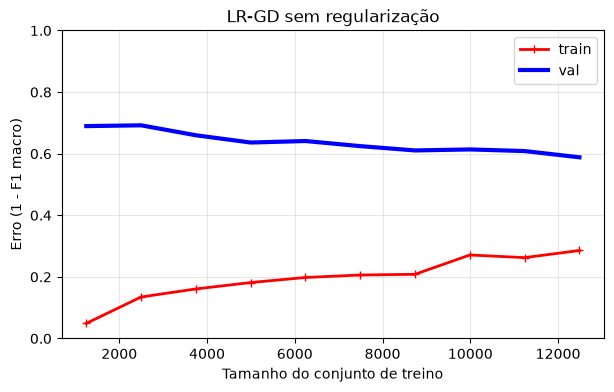

Último ponto -> erro treino: 0.286 | erro validação: 0.588


In [18]:
plot_learning_curves(nova_lr("sem_reg"), X_train_tfidf, y_train, X_val_tfidf, y_val, "LR-GD sem regularização")

**Análise:** com poucos dados o erro de treino é quase zero e o de validação é alto (≈0,69): o modelo decora o treino.
Conforme o treino cresce, o erro de treino sobe (≈0,29) e o de validação cai devagar (≈0,59), mas o **gap continua grande** –
sem regularização, o modelo tem alta variância (5000 pesos por classe, livres para crescer). As curvas ainda não se
encontraram num platô: mais dados ainda ajudariam um pouco.

## Gráfico 2: LR-GD com Ridge (L2)

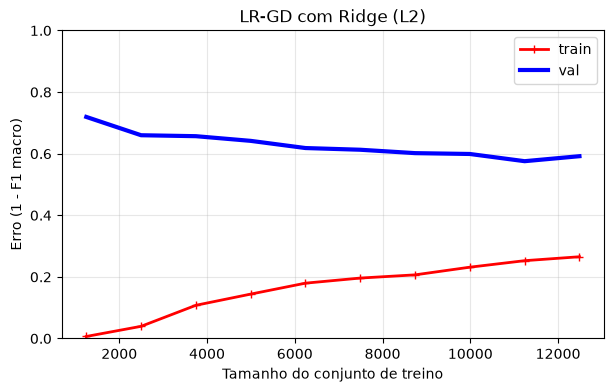

Último ponto -> erro treino: 0.265 | erro validação: 0.592


In [19]:
plot_learning_curves(nova_lr("ridge"), X_train_tfidf, y_train, X_val_tfidf, y_val, "LR-GD com Ridge (L2)")

**Análise:** curva muito parecida com a sem regularização (treino ≈0,27, validação ≈0,59). Com `alpha=1e-4` o Ridge
(L2) só encolhe um pouco os pesos, então o gap diminui pouco. Apesar disso, ele fica mais **preciso** (menos falsos positivos),
como se vê no teste.

## Gráfico 3: LR-GD com Lasso (L1)

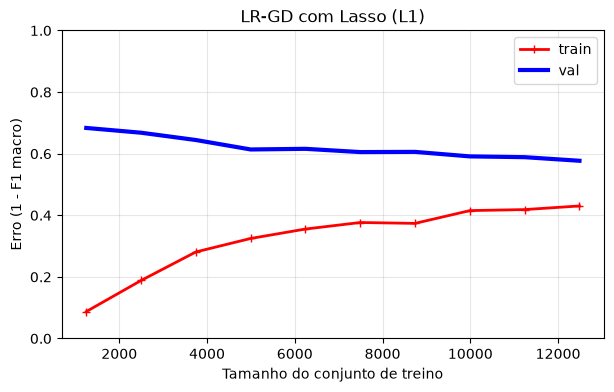

Último ponto -> erro treino: 0.430 | erro validação: 0.577


In [20]:
plot_learning_curves(nova_lr("lasso"), X_train_tfidf, y_train, X_val_tfidf, y_val, "LR-GD com Lasso (L1)")

**Análise:** o Lasso (L1) zera os pesos de muitos termos (seleção de atributos). O erro de treino sobe bem mais
(≈0,43) e o **gap entre treino e validação é o menor das LR** – menos variância, ao custo de mais viés.
A validação (≈0,58) é um pouco melhor que sem regularização.

## Gráfico 4: LR-GD com Elastic Net (L1+L2)

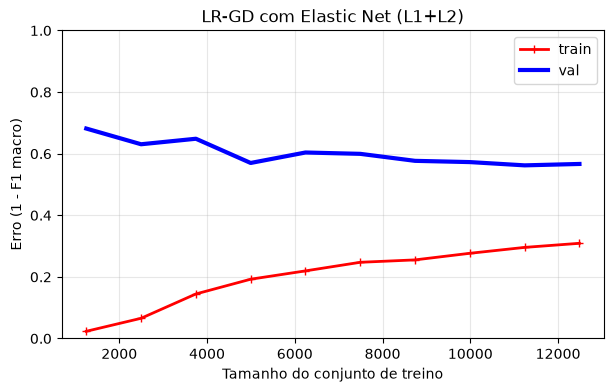

Último ponto -> erro treino: 0.309 | erro validação: 0.567


In [21]:
plot_learning_curves(nova_lr("elastic_net"), X_train_tfidf, y_train, X_val_tfidf, y_val, "LR-GD com Elastic Net (L1+L2)")

**Análise:** o Elastic Net combina L1 e L2 e fica entre Ridge e Lasso no treino (≈0,31), com o **menor erro de
validação** das quatro LR (≈0,57). É o melhor compromisso entre viés e variância, de acordo com a dica dos slides
("de forma geral, Elastic Net mostra resultados melhores que Lasso").

## Gráfico 5: Árvore de Decisão – aumento da altura

Aqui o eixo X é a **profundidade máxima** da árvore (capacidade do modelo), com o treino completo.
Primeiro a árvore é treinada sem limite para descobrir a **altura limite** (até onde ela cresce sozinha
quando todos os nós ficam puros); depois a profundidade é aumentada até essa altura.

In [22]:
# ## Altura limite: árvore sem restrição de profundidade

arvore_completa = ArvoreDecisao(max_depth=None).fit(X_train_tfidf, y_train)
ALTURA_LIMITE = arvore_completa.altura()
print("Altura limite da árvore:", ALTURA_LIMITE)

Altura limite da árvore: 246


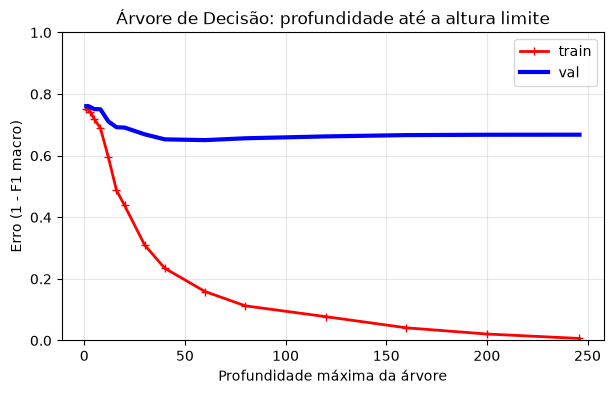

 profundidade  erro_treino  erro_validacao
            1        0.750           0.761
            2        0.750           0.761
            3        0.743           0.758
            5        0.718           0.751
            8        0.690           0.751
           12        0.594           0.711
           16        0.488           0.692
           20        0.439           0.691
           30        0.310           0.669
           40        0.234           0.653
           60        0.159           0.651
           80        0.113           0.657
          120        0.077           0.663
          160        0.041           0.667
          200        0.021           0.668
          246        0.007           0.668

Profundidade com menor erro na validação: 60


In [23]:
# ## Curva de aprendizado da AD: erro no treino e validação em função da profundidade

profundidades = [1, 2, 3, 5, 8, 12, 16, 20, 30, 40, 60, 80, 120, 160, 200, ALTURA_LIMITE]
profundidades = sorted(set(p for p in profundidades if p <= ALTURA_LIMITE))

train_errors, val_errors, arvores = [], [], {}
for d in profundidades:
    arvores[d] = arvore_completa if d == ALTURA_LIMITE else ArvoreDecisao(max_depth=d).fit(X_train_tfidf, y_train)
    train_errors.append(1 - f1_score(y_train, arvores[d].predict(X_train_tfidf), average="macro"))
    val_errors.append(1 - f1_score(y_val, arvores[d].predict(X_val_tfidf), average="macro"))

plt.figure(figsize=(7, 4))
plt.plot(profundidades, train_errors, "r-+", linewidth=2, label="train")
plt.plot(profundidades, val_errors, "b-", linewidth=3, label="val")
plt.xlabel("Profundidade máxima da árvore")
plt.ylabel("Erro (1 - F1 macro)")
plt.title("Árvore de Decisão: profundidade até a altura limite")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(pd.DataFrame({"profundidade": profundidades,
                    "erro_treino": np.round(train_errors, 3),
                    "erro_validacao": np.round(val_errors, 3)}).to_string(index=False))

MELHOR_PROF = profundidades[int(np.argmin(val_errors))]
print("\nProfundidade com menor erro na validação:", MELHOR_PROF)

**Análise:** é o gráfico clássico de viés × variância da aula:

* **Árvores rasas (1–8)**: erro alto e quase igual em treino e validação (≈0,75) → **alto viés / underfitting**: a árvore
  praticamente só prevê `nenhuma` e alguns palavrões óbvios.
* **Profundidade ~40–60**: menor erro de validação (≈0,65) → capacidade adequada.
* **Até a altura limite (246)**: o erro de treino vai a quase zero (a árvore decora o treino), mas a validação piora
  levemente e estabiliza → **alta variância / overfitting**.

A altura limite é muito grande porque, com TF-IDF, cada corte separa poucos tweets (os que contêm um termo raro),
gerando uma árvore longa e desbalanceada. A profundidade escolhida pela validação é usada nas próximas etapas.

# Análise de consistência (30%, 60% e 90% do treino)

Os dois algoritmos (LR-GD sem regularização e AD com a profundidade escolhida na validação) são treinados com
30%, 60% e 90% da parte de treino (que corresponde a 60% do todo) e avaliados no treino usado e na validação.

In [24]:
# ## Consistência: LR-GD e AD com 30%, 60% e 90% do treino

linhas = []
for frac in [0.3, 0.6, 0.9]:
    m = int(frac * X_train_tfidf.shape[0])
    for nome_alg, modelo in [("LR-GD", nova_lr("sem_reg")), ("AD", ArvoreDecisao(max_depth=MELHOR_PROF))]:
        modelo.fit(X_train_tfidf[:m], y_train[:m])
        p_tr = modelo.predict(X_train_tfidf[:m])
        p_va = modelo.predict(X_val_tfidf)
        linhas.append({
            "algoritmo": nome_alg, "% treino": f"{int(frac*100)}%", "n": m,
            "F1 micro treino": f1_score(y_train[:m], p_tr, average="micro"),
            "F1 macro treino": f1_score(y_train[:m], p_tr, average="macro"),
            "F1 micro val": f1_score(y_val, p_va, average="micro"),
            "F1 macro val": f1_score(y_val, p_va, average="macro"),
        })

consistencia = pd.DataFrame(linhas).sort_values(["algoritmo", "n"]).reset_index(drop=True)
consistencia.round(3)

,algoritmo,% treino,n,F1 micro treino,F1 macro treino,F1 micro val,F1 macro val
0,AD,30%,3746,0.977,0.952,0.775,0.335
1,AD,60%,7492,0.965,0.889,0.787,0.364
2,AD,90%,11238,0.957,0.853,0.781,0.367
3,LR-GD,30%,3746,0.971,0.839,0.756,0.340
4,LR-GD,60%,7492,0.944,0.794,0.763,0.375
5,LR-GD,90%,11238,0.909,0.737,0.761,0.391


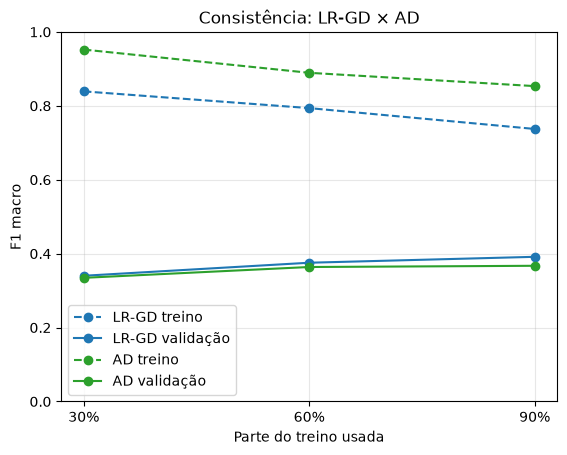

In [25]:
# ## Gráfico da consistência: F1 macro na validação conforme cresce o treino

for alg, cor in [("LR-GD", "tab:blue"), ("AD", "tab:green")]:
    sub = consistencia[consistencia["algoritmo"] == alg]
    plt.plot(sub["% treino"], sub["F1 macro treino"], "--o", color=cor, label=f"{alg} treino")
    plt.plot(sub["% treino"], sub["F1 macro val"], "-o", color=cor, label=f"{alg} validação")
plt.ylabel("F1 macro")
plt.xlabel("Parte do treino usada")
plt.title("Consistência: LR-GD × AD")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Análise:** os dois algoritmos são **consistentes**: ao aumentar o treino de 30% → 60% → 90%, o desempenho de treino
cai (fica mais difícil decorar) e o de validação sobe, ou seja, o gap entre treino e validação diminui.

* **LR-GD**: F1 macro na validação 0,340 → 0,375 → 0,391, ainda subindo – mais dados ainda trariam ganho.
* **AD**: 0,335 → 0,364 → 0,367, praticamente estabiliza entre 60% e 90%, e o gap continua enorme (treino 0,85 × val 0,37),
  sinal da alta variância da árvore.

O F1 micro (≈0,76–0,79) quase não muda porque é dominado pela classe `nenhuma` (80% dos dados).

# Avaliação no teste

Todos os modelos dos gráficos são treinados com o treino completo e avaliados **uma única vez** no teste com
precision, recall (média macro), F1 micro e F1 macro. Para a AD são avaliadas duas árvores do gráfico 5:
a de melhor profundidade na validação e a de altura limite.

In [26]:
# ## Métricas no teste: precision, recall, F1 micro e F1 macro

from sklearn.metrics import precision_score, recall_score, classification_report

modelos_finais = {f"LR-GD {n}": nova_lr(n).fit(X_train_tfidf, y_train) for n in configs}
modelos_finais[f"AD prof={MELHOR_PROF}"] = arvores[MELHOR_PROF]
modelos_finais[f"AD altura limite ({ALTURA_LIMITE})"] = arvore_completa

pred_test = {nome: m.predict(X_test_tfidf) for nome, m in modelos_finais.items()}

resultados = pd.DataFrame([{
    "modelo": nome,
    "precision (macro)": precision_score(y_test, p, average="macro", zero_division=0),
    "recall (macro)": recall_score(y_test, p, average="macro", zero_division=0),
    "F1 micro": f1_score(y_test, p, average="micro"),
    "F1 macro": f1_score(y_test, p, average="macro"),
} for nome, p in pred_test.items()]).set_index("modelo")
resultados.round(3)

,precision (macro),recall (macro),F1 micro,F1 macro
modelo,,,,
LR-GD sem_reg,0.405,0.474,0.774,0.425
LR-GD ridge,0.503,0.448,0.817,0.469
LR-GD lasso,0.442,0.521,0.793,0.455
LR-GD elastic_net,0.505,0.492,0.817,0.493
AD prof=60,0.523,0.373,0.800,0.419
AD altura limite (246),0.442,0.394,0.775,0.414


In [27]:
# ## Relatório por classe no teste (cada modelo)

for nome, p in pred_test.items():
    print(f"===== {nome} =====")
    print(classification_report(y_test, p, zero_division=0, digits=3))

===== LR-GD sem_reg =====
                  precision    recall  f1-score   support

      homophobia      0.288     0.500     0.366        34
          insult      0.395     0.413     0.404       298
         nenhuma      0.882     0.864     0.873      3357
         obscene      0.407     0.385     0.395       455
odio_identitario      0.055     0.211     0.087        19

        accuracy                          0.774      4163
       macro avg      0.405     0.474     0.425      4163
    weighted avg      0.787     0.774     0.780      4163

===== LR-GD ridge =====
                  precision    recall  f1-score   support

      homophobia      0.516     0.471     0.492        34
          insult      0.507     0.356     0.418       298
         nenhuma      0.870     0.933     0.901      3357
         obscene      0.483     0.321     0.386       455
odio_identitario      0.136     0.158     0.146        19

        accuracy                          0.817      4163
       macro avg 

**Análise:**

* **Melhor modelo: LR-GD com Elastic Net** (F1 macro 0,493, F1 micro 0,817), coerente com a curva de aprendizado.
* **A regularização ajuda**: todas as LR regularizadas superam a sem regularização no F1 macro (0,425). Ridge e Elastic Net
  aumentam a precision; Lasso tem o maior recall (0,521), principalmente em `homophobia` (0,735).
* **AD**: F1 micro bom (0,800), mas F1 macro mais baixo (0,419), com a **maior precision (0,523) e o menor recall (0,373)**:
  quando a árvore prevê uma classe tóxica geralmente acerta, mas deixa passar muitos tweets tóxicos como `nenhuma`.
  A árvore de altura limite é um pouco pior que a de profundidade escolhida (overfitting).
* **F1 micro × F1 macro**: o micro (≈0,77–0,82) é puxado pela classe `nenhuma`; o macro (≈0,41–0,49) mostra a dificuldade
  real nas classes pequenas, especialmente `odio_identitario` (19 tweets no teste, F1 ≤ 0,22 em todos os modelos).

# Matrizes de confusão dos três modelos mais significativos

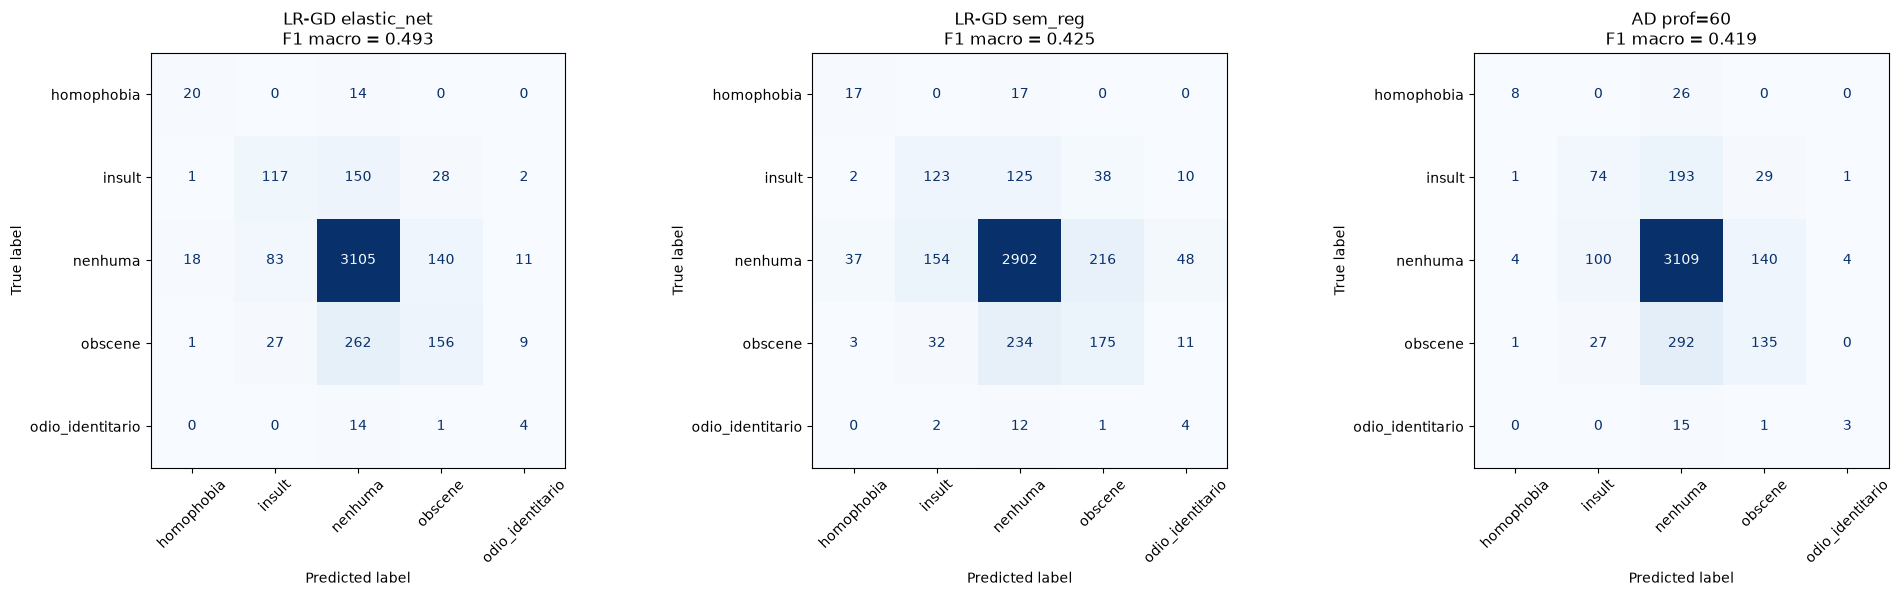

In [28]:
# ## Matrizes de confusão: melhor LR-GD, LR-GD sem regularização e melhor AD

from sklearn.metrics import ConfusionMatrixDisplay

melhor_lr = resultados.loc[[i for i in resultados.index if i.startswith("LR-GD")], "F1 macro"].idxmax()
escolhidos = [melhor_lr, "LR-GD sem_reg", f"AD prof={MELHOR_PROF}"]

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, nome in zip(axes, escolhidos):
    ConfusionMatrixDisplay.from_predictions(y_test, pred_test[nome], ax=ax, cmap="Blues",
                                            xticks_rotation=45, colorbar=False)
    ax.set_title(f"{nome}\nF1 macro = {resultados.loc[nome, 'F1 macro']:.3f}")
plt.tight_layout()
plt.show()

**Análise:** os três modelos escolhidos mostram o efeito da regularização (sem reg × melhor LR) e a diferença entre os algoritmos (LR × AD).

* **Principal erro em todos: tóxico previsto como `nenhuma`** (coluna `nenhuma`). A AD é a que mais faz isso
  (193 insultos e 292 obscenos viram `nenhuma`), o que explica seu recall baixo.
* **LR sem regularização** erra mais no sentido oposto: 216 + 154 + 48 tweets normais classificados como tóxicos (falsos alarmes).
  O Elastic Net reduz bastante esses falsos alarmes.
* **`insult` × `obscene`** se confundem entre si (palavrões aparecem nos dois), o que é esperado: no próprio ToLD-Br um tweet
  pode ter as duas categorias, e aqui escolhemos só a mais votada.
* `homophobia` é a classe minoritária mais fácil (vocabulário específico); `odio_identitario` quase sempre vira `nenhuma`.

# Visão binária: tóxico × não tóxico

Juntando as quatro classes tóxicas, as mesmas predições respondem à pergunta original do ToLD-Br:
o tweet é tóxico ou não?

In [29]:
# ## Métricas binárias no teste (tóxico = qualquer classe diferente de "nenhuma")

toxico_real = y_test != "nenhuma"
binario = pd.DataFrame([{
    "modelo": nome,
    "precision (tóxico)": precision_score(toxico_real, p != "nenhuma"),
    "recall (tóxico)": recall_score(toxico_real, p != "nenhuma"),
    "F1 (tóxico)": f1_score(toxico_real, p != "nenhuma"),
    "F1 macro (binário)": f1_score(toxico_real, p != "nenhuma", average="macro"),
} for nome, p in pred_test.items()]).set_index("modelo")
binario.round(3)

,precision (tóxico),recall (tóxico),F1 (tóxico),F1 macro (binário)
modelo,,,,
LR-GD sem_reg,0.479,0.519,0.498,0.686
LR-GD ridge,0.601,0.421,0.495,0.698
LR-GD lasso,0.519,0.499,0.509,0.697
LR-GD elastic_net,0.592,0.454,0.514,0.707
AD prof=60,0.530,0.347,0.420,0.655
AD altura limite (246),0.459,0.392,0.423,0.648


In [30]:
# ## Exemplos: predição de tweets novos com o melhor modelo LR-GD e a melhor AD

exemplos = ["que jogo lindo, parabéns ao time",
            "cala a boca seu idiota",
            "vai tomar no cu porra",
            "bom dia, que dia bonito hoje"]
X_ex = tfidf.transform(exemplos)
print(pd.DataFrame({"tweet": exemplos,
                    melhor_lr: modelos_finais[melhor_lr].predict(X_ex),
                    f"AD prof={MELHOR_PROF}": arvores[MELHOR_PROF].predict(X_ex)}).to_string(index=False))

                           tweet LR-GD elastic_net AD prof=60
que jogo lindo, parabéns ao time           nenhuma    nenhuma
          cala a boca seu idiota            insult     insult
           vai tomar no cu porra           obscene    obscene
    bom dia, que dia bonito hoje           nenhuma    nenhuma


**Análise:** na pergunta "o tweet é tóxico?", o melhor modelo é novamente a **LR-GD Elastic Net** (F1 macro binário 0,707),
com a AD em 0,655. Comparação com o repositório original do ToLD-Br (que usa modelos BERT na tarefa binária): o ToLD-Br considera tóxico quando **ao menos 1**
anotador marcou alguma categoria; aqui exigimos **2 anotadores concordando**, o que torna os rótulos mais confiáveis, porém
a classe tóxica fica menor.

# Conclusão

* A base é **muito desbalanceada** (80% `nenhuma`), por isso o **F1 macro** é a métrica mais honesta; o F1 micro
  (= acurácia) fica alto mesmo para modelos que erram muito nas classes tóxicas.
* **TF-IDF + LR-GD com Elastic Net** foi o melhor modelo (F1 macro 0,493 em 5 classes; 0,707 em tóxico × não tóxico).
* A **regularização** reduziu a variância das LR (gap menor nas curvas) e melhorou o teste.
* A **Árvore de Decisão implementada do zero** (CART com Gini) se comportou como esperado pela teoria: árvores rasas
  têm alto viés e árvores profundas decoram o treino; a melhor profundidade foi encontrada pela validação. Ela é mais
  interpretável (os primeiros cortes são palavrões como "cu", "da puta", "buceta"), mas tem recall baixo para as classes tóxicas.
* Ambos os algoritmos são **consistentes** (melhoram com mais dados), e a LR ainda não chegou ao platô.
* Limitações: classes de ódio identitário têm pouquíssimos exemplos; ironia, contexto e palavrões usados de forma
  amigável ("vai se fuder aaaa 😍") não são capturados por TF-IDF.